Almost everything in this course comes back to one molecule. Bioinformatics reads it, cancer genomics hunts for typos in it, CRISPR edits it, gene therapy delivers it, and deep learning models now try to predict what each stretch of it does. This chapter explains what DNA is, chemically and as information, and gets you reading real genomes as text.

:::eli5
DNA is a very long instruction book written with only four letters: **A**, **C**, **G** and **T**. It comes as two strands twisted together like a ladder. The two strands are mirror copies: wherever one has A, the other has T, and wherever one has G, the other has C. Because of that rule, if you tear the ladder down the middle, each half has all the information needed to rebuild the other half. That is how a cell copies its DNA before it divides.
:::

## The building block: a nucleotide

DNA (**deoxyribonucleic acid**) is a polymer: a long chain of repeating units called **nucleotides**. Each nucleotide has three parts:

| Part | What it is | Role |
|---|---|---|
| **Phosphate** | a phosphorus atom with four oxygens, negatively charged | links one nucleotide to the next; makes DNA strongly negative |
| **Sugar** (deoxyribose) | a five-carbon ring; its carbons are numbered 1′ to 5′ | the backbone; the numbering gives the strand a direction |
| **Base** | one of four flat, ring-shaped molecules | carries the information |

The four bases come in two shapes:

- **Purines** (two rings): **A**denine and **G**uanine.
- **Pyrimidines** (one ring): **C**ytosine and **T**hymine.

Nucleotides join through their phosphates, linking the 3′ carbon of one sugar to the 5′ carbon of the next. The result is a **sugar–phosphate backbone** with the bases sticking out to the side, like charms on a bracelet. One end of the chain has a free 5′ phosphate (the **5′ end**) and the other a free 3′ hydroxyl (the **3′ end**). By convention, a DNA sequence is always written from 5′ to 3′.

:::bio
**RNA** is the same idea with two differences: its sugar is ribose (one extra oxygen, which makes RNA less stable) and it uses **U**racil instead of T. Most RNA is single-stranded. Chapter P4 is about RNA. Many viruses, including SARS-CoV-2 and influenza, store their genome as RNA rather than DNA. Databases still write RNA genomes with T instead of U, which is why the SARS-CoV-2 file below contains Ts.
:::

## The double helix

In 1953 James Watson and Francis Crick, using X-ray photographs taken by Rosalind Franklin and Maurice Wilkins, worked out that DNA is two strands wound around each other in a **double helix**. Three facts make it work:

1. **Base pairing.** The bases point inward and pair across the strands: **A with T** (two hydrogen bonds) and **G with C** (three hydrogen bonds). A purine always pairs with a pyrimidine, so every rung of the ladder is the same width (about 2 nm).
2. **Antiparallel strands.** The two strands run in opposite directions: one 5′→3′, the other 3′→5′.
3. **Stacking.** The flat bases stack on each other like a pile of coins. Stacking, not hydrogen bonding, provides most of the helix's stability.

One full turn of the helix is about 10.5 base pairs and 3.4 nm long, so each base pair adds **0.34 nm** of length. Remember that number; we use it below.

Because of base pairing, the two strands are **complementary**: one fully determines the other. The partner of a sequence, written in the standard 5′→3′ direction, is its **reverse complement**: complement every base, then reverse the order.

```
5′-ATGCGTAC-3′      top strand
3′-TACGCATG-5′      bottom strand (complement, read right to left)
bottom strand written 5′→3′:  GTACGCAT   = reverse complement of the top
```

Try it yourself: type any sequence and watch the second strand, the hydrogen bonds and the melting temperature change.

::playground animations/dna_lab.html 600

## Reading a real genome

Genomes are stored as plain text in the **FASTA** format: a header line starting with `>`, then the sequence. We downloaded three files from NCBI, the US national sequence database (chapter 1 of Part 1 shows how to fetch any of the hundreds of millions of sequences there):

- **phage lambda** (NC_001416): a virus that infects *E. coli*, with a double-stranded DNA genome. It was one of the first genomes ever sequenced (1982) and is still used in labs as a size marker.
- **SARS-CoV-2** (NC_045512): the COVID-19 virus, with a single-stranded RNA genome.
- **human TP53 mRNA** (NM_000546): the message copied from *TP53*, the most frequently mutated gene in human cancer.

A FASTA reader takes only a few lines of plain Python:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from collections import Counter

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

def read_fasta(path):
    """Return (header, sequence) for a single-record FASTA file."""
    lines = Path(path).read_text().splitlines()
    header = lines[0][1:]                                   # drop the '>'
    seq = "".join(line.strip() for line in lines[1:]).upper()
    return header, seq

genomes = {}
for name, acc in [("phage lambda", "NC_001416"), ("SARS-CoV-2", "NC_045512"), ("TP53 mRNA", "NM_000546")]:
    header, seq = read_fasta(f"datasets/{acc}.fasta")
    genomes[name] = seq
    print(f"{name:13s} {len(seq):>7,} letters   {header[:70]}")
    print(" " * 14, seq[:60], "...")
R["lambda_len"] = f"{len(genomes['phage lambda']):,}"
R["sars_len"] = f"{len(genomes['SARS-CoV-2']):,}"

phage lambda   48,502 letters   NC_001416.1 Enterobacteria phage lambda, complete genome
               GGGCGGCGACCTCGCGGGTTTTCGCTATTTATGAAAATTTTCCGGTTTAAGGCGTTTCCG ...
SARS-CoV-2     29,903 letters   NC_045512.2 Severe acute respiratory syndrome coronavirus 2 isolate Wu
               ATTAAAGGTTTATACCTTCCCAGGTAACAAACCAACCAACTTTCGATCTCTTGTAGATCT ...
TP53 mRNA       2,512 letters   NM_000546.6 Homo sapiens tumor protein p53 (TP53), transcript variant 
               CTCAAAAGTCTAGAGCCACCGTCCAGGGAGCAGGTAGCTGCTGGGCTCCGGGGACACTTT ...


The lambda genome is 48,502 letters and SARS-CoV-2 is 29,903. To a computer, a genome is just a string, and much of bioinformatics is clever string processing. The professional tool for this is **Biopython**, which reads every common format and knows the biology (the genetic code, for example). The same file in Biopython:

In [2]:
from Bio import SeqIO
record = SeqIO.read("datasets/NC_001416.fasta", "fasta")
print(record.id, "|", len(record.seq), "bases")
print(record.seq[:30], "-> reverse complement of the first 30:", record.seq[:30].reverse_complement())

NC_001416.1 | 48502 bases
GGGCGGCGACCTCGCGGGTTTTCGCTATTT -> reverse complement of the first 30: AAATAGCGAAAACCCGCGAGGTCGCCGCCC


## Chargaff's rules: a test of base pairing

Before the double helix was known, Erwin Chargaff measured the bases in DNA from many species and found a puzzling pattern: the amount of A always equalled the amount of T, and G always equalled C. Base pairing explains it at once: every A on one strand has a T opposite it.

But a sequence file holds only **one** strand. Does the rule hold there? Let's count.

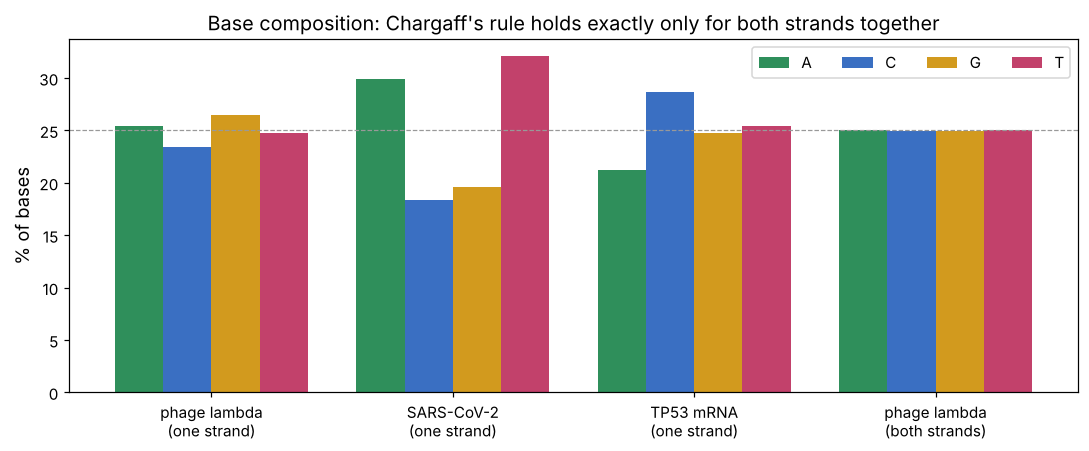

phage lambda (one strand)      A/T = 1.029   G/C = 1.128
SARS-CoV-2 (one strand)        A/T = 0.933   G/C = 1.068
TP53 mRNA (one strand)         A/T = 0.833   G/C = 0.862
phage lambda (both strands)    A/T = 1.000   G/C = 1.000


In [3]:
def composition(seq):
    c = Counter(seq)
    return {b: c[b] / len(seq) for b in "ACGT"}

def revcomp(seq):
    comp = {"A": "T", "T": "A", "G": "C", "C": "G", "N": "N"}
    return "".join(comp[b] for b in reversed(seq))

rows = {}
for name, seq in genomes.items():
    rows[name + "\n(one strand)"] = composition(seq)
lam = genomes["phage lambda"]
rows["phage lambda\n(both strands)"] = composition(lam + revcomp(lam))

fig, ax = plt.subplots(figsize=(10, 4.2))
colours = {"A": "#2f8f5b", "C": "#3a6fc2", "G": "#d29a1e", "T": "#c2416b"}
labels = list(rows)
for j, b in enumerate("ACGT"):
    ax.bar(np.arange(len(labels)) + (j - 1.5) * 0.2, [rows[k][b] * 100 for k in labels], 0.2, color=colours[b], label=b)
ax.set_xticks(range(len(labels)), labels); ax.set_ylabel("% of bases"); ax.axhline(25, color="0.6", lw=0.8, ls="--")
ax.legend(ncol=4); ax.set_title("Base composition: Chargaff's rule holds exactly only for both strands together")
save_fig("chargaff"); plt.show()

for k, v in rows.items():
    print(f"{k.replace(chr(10), ' '):30s} A/T = {v['A'] / v['T']:.3f}   G/C = {v['G'] / v['C']:.3f}")
both = rows["phage lambda\n(both strands)"]
R["lam_at"] = f"{rows['phage lambda' + chr(10) + '(one strand)']['A'] / rows['phage lambda' + chr(10) + '(one strand)']['T']:.2f}"
R["sars_t"] = f"{rows['SARS-CoV-2' + chr(10) + '(one strand)']['T']:.0%}"
R["sars_c"] = f"{rows['SARS-CoV-2' + chr(10) + '(one strand)']['C']:.0%}"
R["sars_g"] = f"{rows['SARS-CoV-2' + chr(10) + '(one strand)']['G']:.0%}"
assert abs(both["A"] - both["T"]) < 1e-12 and abs(both["G"] - both["C"]) < 1e-12

![Figure P3-1. Base composition of three real sequences. When both strands of lambda are counted, A equals T and G equals C exactly, as Chargaff found by chemistry. A single strand only roughly follows the rule.](images/chargaff.png)

Three lessons from one chart:

- **Both strands of lambda** obey Chargaff's rule exactly. That is not a fact about lambda; it is guaranteed by base pairing, and the `assert` in the code proves it.
- **One strand of lambda** is close (A/T = 1.03) but not exact. Long double-stranded genomes tend to be roughly balanced on each strand too, an observation called Chargaff's *second* rule, but nothing forces it.
- **SARS-CoV-2**, a single-stranded RNA virus, is lopsided: 32% T (really U) but only 18% C against 20% G. One explanation is that human antiviral enzymes (APOBEC proteins) attack the virus by converting C to U, and over many generations the genome drifts towards fewer Cs. Chapter P10 meets these enzymes as part of the immune system, and chapter P12 meets them again as a source of mutations in cancer.

## GC content and why it matters

The fraction of G and C bases is the **GC content**. A G–C pair has three hydrogen bonds and stacks more strongly than A–T, so GC-rich DNA is harder to pull apart (to **melt**, or **denature**). GC content varies a lot: between species (from about 20% to 75% in bacteria) and along a single genome. A sliding window shows the variation along lambda:

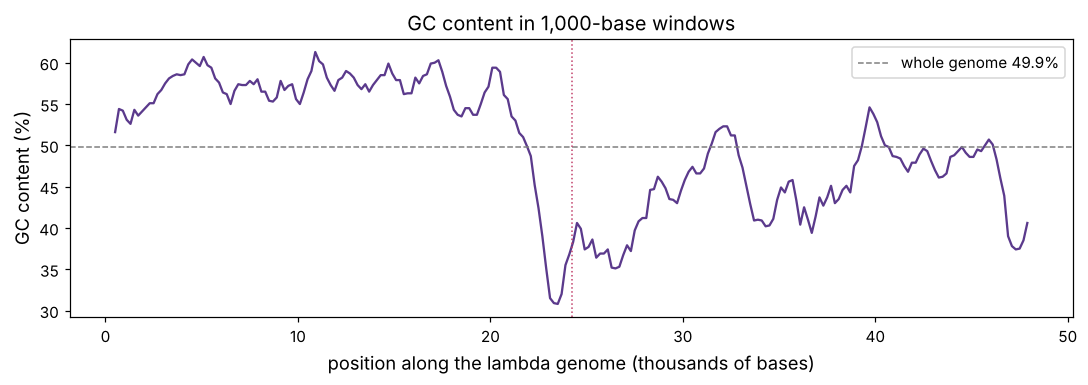

left half 54.9%, right half 44.8%


In [4]:
def gc(seq):
    return (seq.count("G") + seq.count("C")) / len(seq)

win, step = 1000, 200
pos = np.arange(0, len(lam) - win, step)
gcs = np.array([gc(lam[p:p + win]) for p in pos])

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot((pos + win / 2) / 1000, gcs * 100, color="#5b3a8c")
ax.axhline(gc(lam) * 100, color="0.5", ls="--", lw=1, label=f"whole genome {gc(lam):.1%}")
ax.axvline(len(lam) / 2000, color="#c2416b", lw=1, ls=":")
ax.set_xlabel("position along the lambda genome (thousands of bases)"); ax.set_ylabel("GC content (%)")
ax.set_title("GC content in 1,000-base windows"); ax.legend()
save_fig("gc_window"); plt.show()
half = len(lam) // 2
R["gc_all"] = f"{gc(lam):.1%}"
R["gc_left"] = f"{gc(lam[:half]):.0%}"
R["gc_right"] = f"{gc(lam[half:]):.0%}"
print(f"left half {gc(lam[:half]):.1%}, right half {gc(lam[half:]):.1%}")

![Figure P3-2. GC content along phage lambda in 1,000-base windows. The left half, which carries the genes for building the virus particle, is noticeably more GC-rich than the right half.](images/gc_window.png)

Lambda as a whole is 49.9% GC, but its left half is about 55% and its right half about 45%. The left half holds the genes for the virus's head and tail; the right half holds genes for recombination, regulation and bursting out of the host. Shifts in GC content like this often hint that parts of a genome have different evolutionary histories. Local GC content is a clue to a sequence's function and history, and you'll use it in Part 1.

In the lab, GC content sets the **melting temperature** (Tm), the temperature at which half the DNA has separated into single strands. Short DNA pieces called **primers** must stick to the right place during PCR (chapter P11), so they are designed with about 40–60% GC and a Tm around 55–65 °C. The quick rule used in the playground above, for short primers:

:::math
**Wallace rule** (primers under about 14 bases): $T_m \approx 2\,(\#A + \#T) + 4\,(\#G + \#C)\ ^\circ\text{C}$.

For longer primers a common approximation is $T_m \approx 64.9 + 41\,\dfrac{\#G + \#C - 16.4}{N}$, with $N$ the length. Real primer-design software uses nearest-neighbour thermodynamics, which accounts for which bases are stacked next to each other.
:::

In [5]:
def tm(primer):
    n, g = len(primer), primer.count("G") + primer.count("C")
    return 2 * (n - g) + 4 * g if n < 14 else 64.9 + 41 * (g - 16.4) / n

for p in ["ATGCGTACGTTAGC", "AAATTTAATATTTAAATTAT", "GCGGCCGCGGGCCCGCGC", "TGGAATTCGCATGCAGTCGA"]:
    print(f"{p:22s} length {len(p):2d}  GC {gc(p):4.0%}  Tm about {tm(p):4.0f} °C")

ATGCGTACGTTAGC         length 14  GC  50%  Tm about   37 °C
AAATTTAATATTTAAATTAT   length 20  GC   0%  Tm about   31 °C
GCGGCCGCGGGCCCGCGC     length 18  GC 100%  Tm about   69 °C
TGGAATTCGCATGCAGTCGA   length 20  GC  50%  Tm about   52 °C


The AT-only primer melts at about 31 °C and would fall off at PCR temperatures; the GC-only one sticks so strongly that it also binds to places it only partly matches, which is just as bad. Good primers sit in the middle.

## Reverse complements and palindromes

Because either strand can carry a gene, any search through a genome must look at both strands. The reverse complement is therefore one of the most-used functions in bioinformatics. Two properties are worth checking in code:

In [6]:
s = "ATGCCGTATTGCAGG"
print(revcomp(s), "| twice gives back the original:", revcomp(revcomp(s)) == s)
print("EcoRI site GAATTC is its own reverse complement:", revcomp("GAATTC") == "GAATTC")

CCTGCAATACGGCAT | twice gives back the original: True
EcoRI site GAATTC is its own reverse complement: True


A sequence that equals its own reverse complement, like `GAATTC`, is called a **palindrome** (it reads the same on both strands, each read 5′→3′). Bacteria defend themselves against viruses with **restriction enzymes** that cut DNA at specific palindromes. *EcoRI*, from *E. coli*, cuts at every `GAATTC`. Restriction enzymes launched genetic engineering in the 1970s and are still in every molecular biology lab. Where would *EcoRI* cut lambda?

In [7]:
import re
sites = [m.start() for m in re.finditer("GAATTC", lam)]
cuts = [0] + [p + 1 for p in sites] + [len(lam)]           # EcoRI cuts between G and AATTC
frags = sorted((b - a for a, b in zip(cuts, cuts[1:])), reverse=True)
print("EcoRI sites at:", sites)
print("fragment sizes (bp):", frags)
R["n_sites"] = len(sites); R["n_frags"] = len(frags); R["big_frag"] = f"{frags[0]:,}"

EcoRI sites at: [21225, 26103, 31746, 39167, 44971]
fragment sizes (bp): [21226, 7421, 5804, 5643, 4878, 3530]


There are 5 sites, so lambda is cut into 6 pieces, the largest 21,226 base pairs. Those exact fragments are sold as a "lambda *EcoRI* digest" and run alongside unknown samples in gel electrophoresis (chapter P11) as a ruler. You just predicted a lab result from a text file, which is the essence of bioinformatics.

## Packing two metres into a nucleus

How long is the DNA in one human cell? Each base pair is 0.34 nm, and the human genome is about 3.1 billion base pairs per copy. Most cells have two copies (one from each parent).

In [8]:
bp_per_copy, nm_per_bp = 3.1e9, 0.34
length_m = 2 * bp_per_copy * nm_per_bp * 1e-9
nucleus_m = 6e-6
print(f"DNA per cell: {length_m:.1f} m, in a nucleus {nucleus_m * 1e6:.0f} µm across: {length_m / nucleus_m:,.0f} times longer")
cells = 3.7e13
print(f"all the DNA in your body end to end: {length_m * cells / 1.496e11:.0f} times the Earth-Sun distance")
bits = 2 * bp_per_copy                                     # 4 letters = 2 bits each
print(f"information per copy: {bits / 8 / 1e6:.0f} MB (2 bits per base)")
R["dna_m"] = f"{length_m:.1f}"; R["ratio"] = f"{length_m / nucleus_m / 1000:,.0f}"; R["mb"] = f"{bits / 8 / 1e6:.0f}"

DNA per cell: 2.1 m, in a nucleus 6 µm across: 351,333 times longer
all the DNA in your body end to end: 521 times the Earth-Sun distance
information per copy: 775 MB (2 bits per base)


About 2.1 metres of DNA fits in a nucleus a few micrometres wide, roughly 351 thousand times longer than the box it is in. Squeezed into a phone file, one copy of the genome is only about 775 MB, less than a film.

The packing is done by proteins in a hierarchy:

1. DNA wraps about 1.7 times (147 base pairs) around a spool of eight **histone** proteins. The spool plus DNA is a **nucleosome**. Strings of nucleosomes look like beads on a string.
2. The beads fold and loop into **chromatin**. Loops are anchored by proteins such as cohesin and CTCF.
3. During cell division, chromatin condenses further into the X-shaped **chromosomes** you have seen in pictures (chapter P7).

Humans have **23 pairs of chromosomes**: 22 pairs of **autosomes** numbered roughly by size, plus the sex chromosomes (XX or XY). Tightly packed chromatin (**heterochromatin**) is hard for the cell to read; loosely packed **euchromatin** is where active genes sit. Chemical tags on histones and on the DNA itself control the packing, and therefore which genes can be read. That is **epigenetics**, in chapter P6.

:::idea
Packing is not just storage. Whether a gene is wrapped up tightly or left open is one of the main ways a neuron and a liver cell, with identical DNA, end up reading different genes. Many cancers carry mutations in the proteins that place and read histone tags.
:::

## Copying DNA

Before a cell divides, it must copy all 6.2 billion base pairs, quickly and almost without mistakes. Replication follows directly from base pairing:

1. **Helicase** unzips the double helix, making a Y-shaped **replication fork**.
2. **Primase** lays down a short RNA primer, because polymerase can only extend an existing strand.
3. **DNA polymerase** reads each old strand and adds the complementary nucleotide to a new strand. It can only build in the **5′→3′ direction**.
4. Because the strands are antiparallel, one new strand (the **leading strand**) is made continuously, while the other (the **lagging strand**) is made backwards in short **Okazaki fragments**, later joined by **DNA ligase**.

Each new double helix contains one old strand and one new one. This is called **semi-conservative replication**. Step through it in the "Copy the DNA" tab of the playground above.

Why does replication start at many places at once? Some arithmetic shows why:

In [9]:
speed = 50                                     # bases added per second per fork (human)
chrom1 = 249e6                                 # chromosome 1, base pairs
one_origin = chrom1 / (2 * speed)              # two forks moving apart from one origin
print(f"chromosome 1 from a single origin: {one_origin / 86400:.0f} days")
origins = 50_000                               # roughly how many origins fire across the genome
per_origin = 2 * bp_per_copy / origins
print(f"with {origins:,} origins: about {per_origin / (2 * speed) / 60:.0f} minutes of copying per origin")
error_rate = 1e-9                              # after proofreading and mismatch repair
print(f"expected new errors per cell division: {error_rate * 2 * bp_per_copy:.0f}")
R["one_origin_days"] = f"{one_origin / 86400:.0f}"
R["errors"] = f"{error_rate * 2 * bp_per_copy:.0f}"

chromosome 1 from a single origin: 29 days
with 50,000 origins: about 21 minutes of copying per origin
expected new errors per cell division: 6


From a single starting point, copying chromosome 1 would take about 29 days. Instead, tens of thousands of **origins of replication** fire across the genome. Each origin needs only minutes of copying, but they fire in waves (open euchromatin early, packed heterochromatin late), so the whole job takes about 8 hours (the S phase of the cell cycle, chapter P7). Even with proofreading and repair, about 6 new mistakes slip in every time a cell divides. Most fall in unimportant places. A few, accumulated over years in the wrong genes, start cancers (chapter P12). Cancer drugs such as 5-fluorouracil and gemcitabine work by jamming DNA replication, which hurts fast-dividing cells most.

## What is written in a genome?

Click the bar in the "What is in a genome" tab of the playground. The surprise is how little of the human genome codes for protein:

| Part | Share of the genome (approximate) |
|---|---|
| Protein-coding exons | about 1–2% |
| Introns (inside genes, spliced out) | about 24% |
| Transposable elements ("jumping genes") | about 45% |
| Regulatory elements (promoters, enhancers) | a few % |
| Other repeats and unassigned | the rest |

A **gene** is a stretch of DNA that is copied into a functional RNA. For protein-coding genes (about 20,000 in humans) a gene contains:

- a **promoter** upstream, where the copying machinery binds (chapter P6),
- **exons**, the pieces kept in the final message, separated by **introns**, which are cut out (chapter P4),
- **untranslated regions** (UTRs) at the start and end of the message, which control how it is used,
- the **coding sequence** (CDS), from a start signal (`ATG`) to a stop signal, which spells out the protein.

The TP53 file is the mature message, with introns already removed. We can find its coding sequence: the first `ATG`, then read three letters at a time until a stop codon. (Chapter P4 explains the three-letter code properly.)

In [10]:
tp53 = genomes["TP53 mRNA"]
start = tp53.find("ATG")
stops = {"TAA", "TAG", "TGA"}
end = next(i for i in range(start, len(tp53) - 2, 3) if tp53[i:i + 3] in stops)
cds = tp53[start:end + 3]
print(f"5′ UTR: {start} bases | coding sequence: {len(cds)} bases = {len(cds) // 3 - 1} amino acids + stop | 3′ UTR: {len(tp53) - end - 3} bases")
print("coding sequence starts:", " ".join(cds[i:i + 3] for i in range(0, 30, 3)), "...")
from Bio.Seq import Seq
print("protein (Biopython):", Seq(cds).translate()[:40], "...")
R["utr5"] = start; R["n_aa"] = len(cds) // 3 - 1; R["utr3"] = len(tp53) - end - 3

5′ UTR: 142 bases | coding sequence: 1182 bases = 393 amino acids + stop | 3′ UTR: 1188 bases
coding sequence starts: ATG GAG GAG CCG CAG TCA GAT CCT AGC GTC ...
protein (Biopython): MEEPQSDPSVEPPLSQETFSDLWKLLPENNVLSPLPSQAM ...


The message has a 5′ UTR of 142 bases, then a coding sequence for a protein of 393 amino acids, then a 3′ UTR of 1188 bases. That protein, p53, is called "the guardian of the genome": it halts the cell cycle when DNA is damaged and, if the damage is too great, tells the cell to kill itself. It is mutated in about half of all human cancers. You will meet it again in nearly every chapter from P7 onward.

:::data
Sequence files you will meet in this course: **FASTA** (sequence only), **FASTQ** (sequencer reads plus a quality score for every base, Part 1), **GenBank** (sequence plus annotations such as where the genes are), **BAM** (reads aligned to a genome), **VCF** (variants: positions where a sample differs from the reference) and **BED/GTF** (coordinates of genes and other features). All of them are text or compressed text.
:::

## Summary

| Idea | One line |
|---|---|
| Nucleotide | phosphate + deoxyribose sugar + one of A, C, G, T |
| Base pairing | A–T (2 hydrogen bonds), G–C (3) |
| Antiparallel | strands run 5′→3′ and 3′→5′; sequences are written 5′→3′ |
| Reverse complement | the other strand, written 5′→3′ |
| GC content | more G–C means a higher melting temperature |
| Packing | about 2 m per cell, wound on histones into chromatin and chromosomes |
| Replication | helicase unzips, polymerase copies 5′→3′, semi-conservative |
| Genome | about 1–2% protein-coding in humans; about 20,000 genes |

:::check
1. A DNA strand reads `5′-GATTACA-3′`. What is its reverse complement? *(`5′-TGTAATC-3′`.)*
2. A double-stranded DNA sample is 30% A. What fractions are T, G and C? *(T 30%, G 20%, C 20%.)*
3. Why can't you apply Chargaff's rule to a single-stranded RNA virus? *(There is no partner strand forcing A to equal T.)*
4. Which is harder to melt, a 20-base primer with 4 Gs and Cs or one with 12? *(The one with 12: more G–C pairs, more hydrogen bonds and stronger stacking.)*
5. Why must the lagging strand be made in pieces? *(Polymerase only builds 5′→3′, and the lagging strand's template is exposed in the opposite direction as the fork opens.)*
:::

:::exercise
The restriction enzyme *BamHI* cuts at `GGATCC`, between the two Gs. (a) Check that the site is a palindrome. (b) Find the fragment sizes it produces from lambda. (c) In random DNA with 25% of each base, how often would you expect a given 6-letter site? Compare with what you found.
:::

<details><summary>Solution</summary>

In [11]:
print("palindrome:", revcomp("GGATCC") == "GGATCC")
bam = [m.start() for m in re.finditer("GGATCC", lam)]
cuts = [0] + [p + 1 for p in bam] + [len(lam)]
print("BamHI sites:", len(bam), "| fragments:", sorted((b - a for a, b in zip(cuts, cuts[1:])), reverse=True))
print(f"expected one site every 4^6 = {4 ** 6:,} bp, so about {len(lam) / 4 ** 6:.0f} sites in lambda")

palindrome: True
BamHI sites: 5 | fragments: [16841, 7233, 6770, 6527, 5626, 5505]
expected one site every 4^6 = 4,096 bp, so about 12 sites in lambda


The site is its own reverse complement. Lambda has five *BamHI* sites, giving six fragments. Random DNA would have a given 6-letter site about once every 4,096 bases, so about 12 in lambda. The real count is much lower, as it is for *EcoRI*. A plausible reason is evolution: phages that infect bacteria carrying these restriction enzymes are under pressure to lose the sites. Real genomes are not random strings, and the differences are biological clues.

</details>